## Install and import libraries

In [1]:
%pip install tensorflow pandas numpy matplotlib scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

Load the dataset

In [4]:
df = pd.read_csv("pima-indians-diabetes.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head(5))

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (767, 9)

First 5 Rows:


,6,148,72,35,0,33.6,0.627,50,1
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0



Missing Values:
6        0
148      0
72       0
35       0
0        0
33.6     0
0.627    0
50       0
1        0
dtype: int64


Handle zero values

In [11]:
import pandas as pd

columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv(
    "pima-indians-diabetes.csv",
    header=None,
    names=columns
)

print("Dataset Shape:", df.shape)
display(df.head(5))

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [12]:
display(df.head())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Replace zero values

In [13]:
columns_to_fix = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in columns_to_fix:
    median_value = df[col].replace(0, float("nan")).median()
    df[col] = df[col].replace(0, median_value)

print("Zero values replaced successfully!")
print(df[columns_to_fix].isnull().sum())

Zero values replaced successfully!
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


Split and scale the data

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (614, 8)
Testing data shape: (154, 8)


## Build your ANN model

In [15]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    tf.keras.Input(shape=(8,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

Train your model

In [16]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 101ms/step - accuracy: 0.4929 - loss: 0.7330 - val_accuracy: 0.4634 - val_loss: 0.7244
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.6130 - loss: 0.6785 - val_accuracy: 0.6016 - val_loss: 0.6749
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6782 - loss: 0.6338 - val_accuracy: 0.6260 - val_loss: 0.6353
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.7128 - loss: 0.6001 - val_accuracy: 0.6748 - val_loss: 0.6042
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.7352 - loss: 0.5729 - val_accuracy: 0.7236 - val_loss: 0.5807
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.7556 - loss: 0.5522 - val_accuracy: 0.7317 - val_loss: 0.5573
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.7515 - loss: 0.5343 - val_accuracy: 0.7317 - val_loss: 0.5434
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.7556 - loss: 0.5206 - val_accuracy: 0.7480 - 

Plot training and validation accuracy

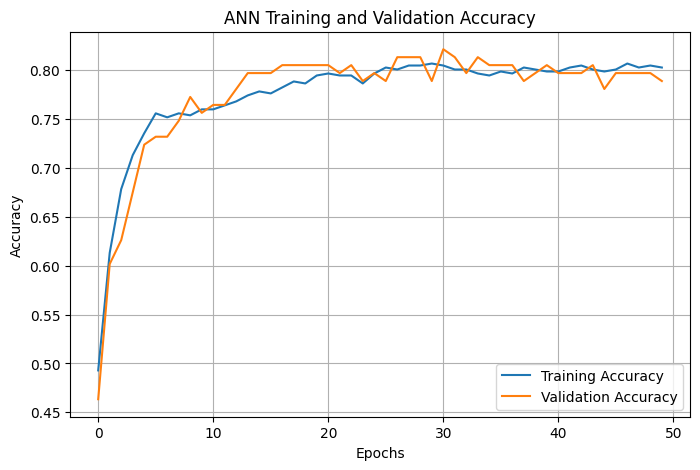

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("ANN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Plot training and validation loss

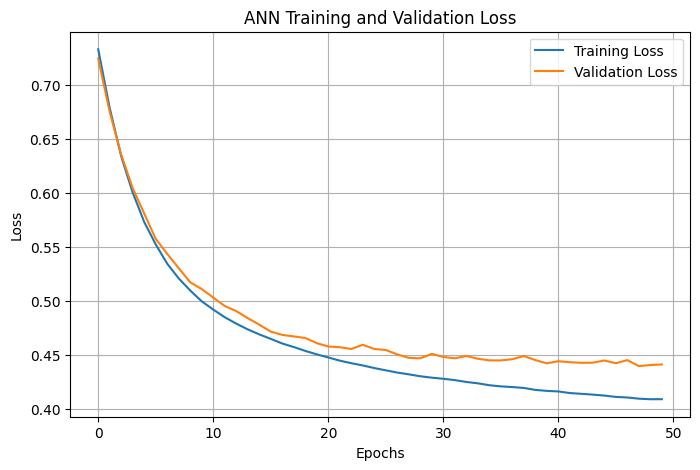

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

Evaluate your ANN on the test set

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step
Test Accuracy: 0.7403
Precision: 0.6346
Recall: 0.6111
F1-Score: 0.6226


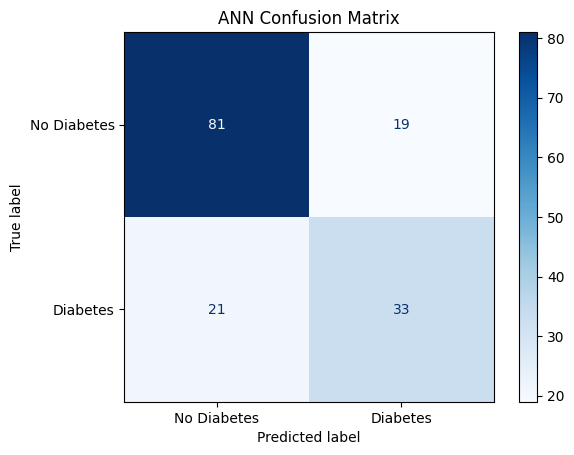

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).flatten()

print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot(cmap="Blues")
plt.title("ANN Confusion Matrix")
plt.show()

Accuracy: The model correctly classified about 74% of the test patients.



Precision: Of the patients predicted as diabetic, about 63% were actually diabetic.



Recall: The model identified about 61% of the patients who had diabetes in the test set.



F1-score: The balance between precision and recall is about 62%.

Save your model

In [21]:
model.save("ann_diabetes_model.h5")
print("ANN model saved successfully!")

ANN model saved successfully!


Add your ANN reflection

### ANN — Reflection

The ANN model was built using the Pima Indians Diabetes dataset, which contains 768 patient records and eight input features. Before training, zero values in selected columns were replaced with their median values. The data was then standardized and divided into training and testing sets.

The model contains two hidden layers with 16 and 8 neurons, respectively. ReLU activation was used in the hidden layers to learn patterns in the data, while sigmoid activation was used in the output layer to predict the probability of diabetes. The Adam optimizer and binary cross-entropy loss were used for training.

The model achieved a test accuracy of 74.03%, precision of 63.46%, recall of 61.11%, and F1-score of 62.26%. The results show that the model can predict diabetes to a reasonable basic level, although some diabetic patients were incorrectly classified. In the future, I could experiment with dropout, different network sizes, and classification thresholds to improve performance.

## Step 2: OpenCV image preprocessing

Import libraries and load image paths

In [23]:
import cv2
import os
import matplotlib.pyplot as plt

image_folder = "images"

image_files = [
    "flower.jpg",
    "dog.jpg",
    "apple.jpg",
    "bicycle.jpg",
    "mug.jpg"
]

images = []

for file in image_files:
    path = os.path.join(image_folder, file)
    img = cv2.imread(path)

    if img is None:
        print("Could not load:", path)
    else:
        images.append((file, img))
        print(file, "Shape:", img.shape)

flower.jpg Shape: (452, 678, 3)
dog.jpg Shape: (640, 480, 3)
apple.jpg Shape: (581, 527, 3)
bicycle.jpg Shape: (1960, 2613, 3)
mug.jpg Shape: (894, 894, 3)


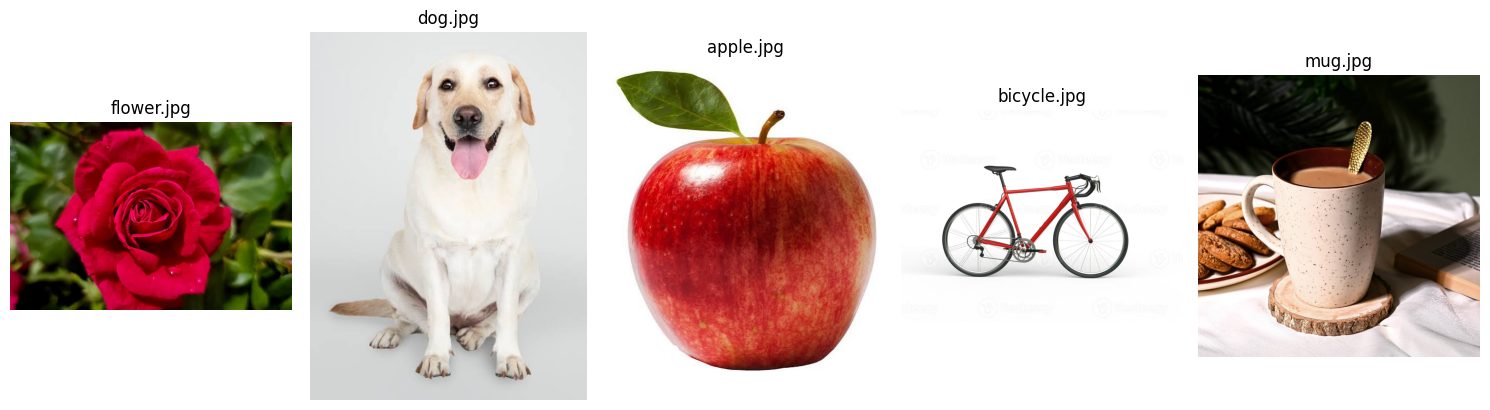

In [24]:
plt.figure(figsize=(15, 4))

for i, (name, img) in enumerate(images):
    plt.subplot(1, 5, i + 1)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img_rgb)
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

Apply all five preprocessing stages

In [25]:
os.makedirs("outputs", exist_ok=True)

processed_images = []

for name, img in images:

    # 1. Resize
    resized = cv2.resize(img, (128, 128))

    # 2. Grayscale
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)

    # 3. Gaussian Blur
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 4. Canny Edge Detection
    edges = cv2.Canny(blurred, 100, 200)

    # 5. Find the largest contour
    contours, hierarchy = cv2.findContours(
        edges.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    contour_img = resized.copy()

    if contours:
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)

        cv2.rectangle(
            contour_img,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    processed_images.append(
        (name, img, resized, gray, edges, contour_img)
    )

    # Save output images
    base_name = os.path.splitext(name)[0]

    cv2.imwrite(f"outputs/{base_name}_resized.jpg", resized)
    cv2.imwrite(f"outputs/{base_name}_grayscale.jpg", gray)
    cv2.imwrite(f"outputs/{base_name}_blurred.jpg", blurred)
    cv2.imwrite(f"outputs/{base_name}_edges.jpg", edges)
    cv2.imwrite(f"outputs/{base_name}_contour.jpg", contour_img)

print("Preprocessing completed!")
print("Output images saved in the outputs folder.")

Preprocessing completed!
Output images saved in the outputs folder.


Create the required 5 × 5 grid

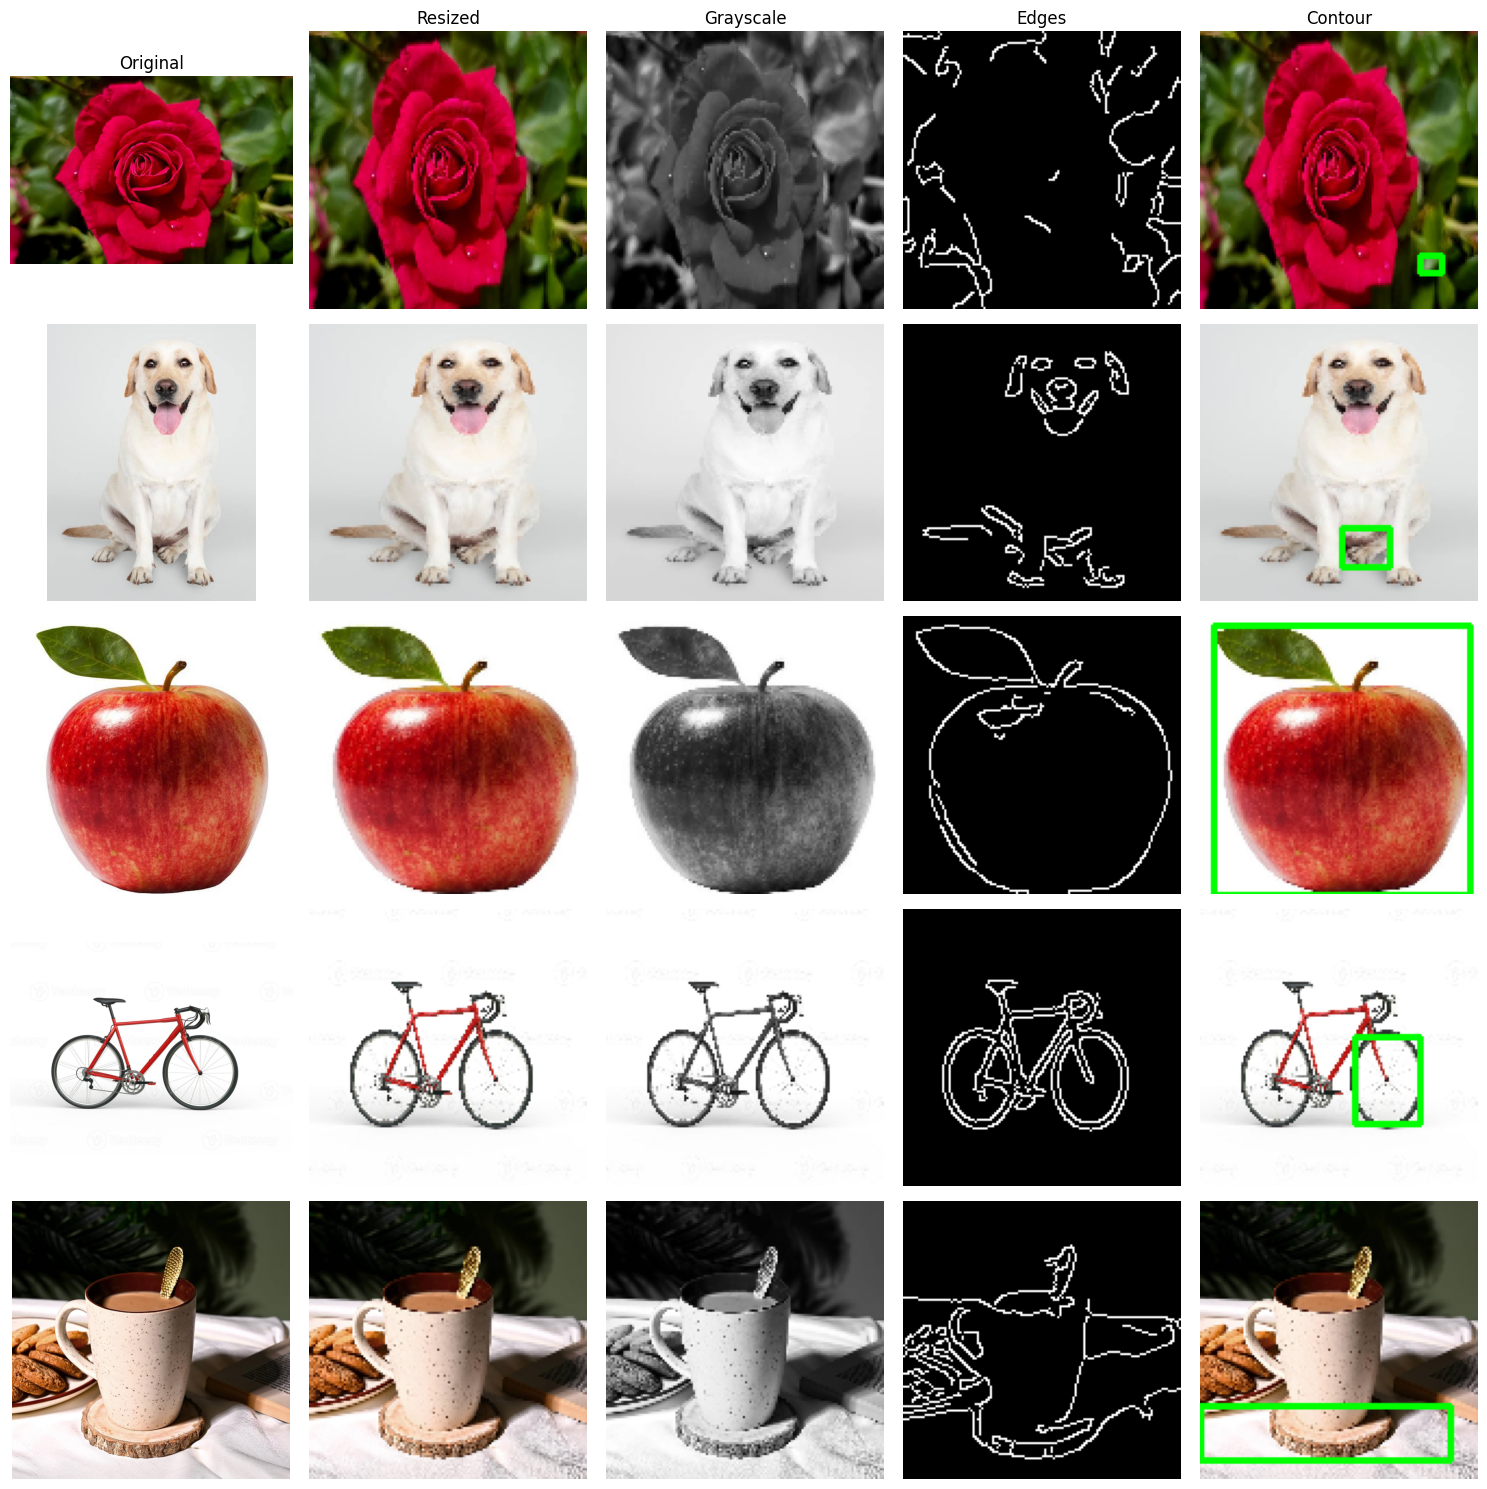

In [26]:
titles = [
    "Original",
    "Resized",
    "Grayscale",
    "Edges",
    "Contour"
]

fig, axes = plt.subplots(5, 5, figsize=(15, 15))

for row, (name, original, resized, gray, edges, contour_img) in enumerate(processed_images):

    images_to_show = [
        cv2.cvtColor(original, cv2.COLOR_BGR2RGB),
        cv2.cvtColor(resized, cv2.COLOR_BGR2RGB),
        gray,
        edges,
        cv2.cvtColor(contour_img, cv2.COLOR_BGR2RGB)
    ]

    for col in range(5):
        axes[row, col].imshow(
            images_to_show[col],
            cmap="gray" if col in [2, 3] else None
        )

        if row == 0:
            axes[row, col].set_title(titles[col])

        if col == 0:
            axes[row, col].set_ylabel(name)

        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig("outputs/opencv_5x5_grid.png", dpi=150)
plt.show()

Explanation

### OpenCV Image Preprocessing — Reflection

- **Resizing:** Changes every image to 128 × 128 pixels so all images have the same dimensions.
- **Grayscale conversion:** Converts a colour image into shades of gray, simplifying image processing.
- **Gaussian blur:** Reduces noise and small details, which can help improve edge detection.
- **Canny edge detection:** Identifies strong changes in image intensity to highlight object boundaries.
- **Contour detection:** Finds outlines of connected shapes. A green bounding rectangle is drawn around the largest detected contour.

These operations are useful before CNN processing because they can standardize image sizes, reduce noise, and highlight important visual structures. However, preprocessing choices depend on the task, and grayscale conversion can remove colour information that may be useful for classification.

## Step 3 — CNN

Import libraries and load CIFAR-10

In [27]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

from sklearn.metrics import classification_report

In [1]:
from pathlib import Path

cache_dir = Path.home() / ".keras" / "datasets"

for file in cache_dir.glob("*"):
    print(file.name, round(file.stat().st_size / (1024 * 1024), 2), "MB")

cifar-10-batches-py-target_archive 89.52 MB


In [2]:
from pathlib import Path

cache_dir = Path.home() / ".keras" / "datasets"

for file in cache_dir.iterdir():
    print("Name:", file.name)
    print("Size:", round(file.stat().st_size / (1024 * 1024), 2), "MB")
    print("Is directory:", file.is_dir())
    print()

Name: cifar-10-batches-py-target_archive
Size: 89.52 MB
Is directory: False



In [3]:
import tarfile
from pathlib import Path

file_path = (
    Path.home()
    / ".keras"
    / "datasets"
    / "cifar-10-batches-py-target_archive"
)

print("File exists:", file_path.exists())
print("File size:", round(file_path.stat().st_size / (1024 * 1024), 2), "MB")

try:
    with tarfile.open(file_path, "r:gz") as archive:
        print("Archive is valid!")
        print("First files:", archive.getnames()[:10])
except Exception as e:
    print("Archive check failed:", repr(e))

File exists: True
File size: 89.52 MB
Archive is valid!
Archive check failed: EOFError('Compressed file ended before the end-of-stream marker was reached')


In [4]:
from pathlib import Path

file_path = (
    Path.home()
    / ".keras"
    / "datasets"
    / "cifar-10-batches-py-target_archive"
)

if file_path.exists():
    file_path.unlink()
    print("Incomplete download removed.")

Incomplete download removed.


In [6]:
import requests

url = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
save_path = "cifar-10-python.tar.gz"

response = requests.get(url, stream=True, timeout=30)
response.raise_for_status()

total = int(response.headers.get("content-length", 0))
downloaded = 0

with open(save_path, "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)
            downloaded += len(chunk)
            print(
                f"\rDownloaded: {downloaded / (1024**2):.1f} MB"
                + (
                    f" / {total / (1024**2):.1f} MB"
                    if total else ""
                ),
                end=""
            )

print("\nDownload complete.")

Downloaded: 162.6 MB / 162.6 MB
Download complete.


In [7]:
import tarfile

with tarfile.open("cifar-10-python.tar.gz", "r:gz") as archive:
    print("Archive is valid:", archive.getmembers()[0].name)

Archive is valid: cifar-10-batches-py


Extract the dataset

In [9]:
import tarfile
import os

archive_path = "cifar-10-python.tar.gz"
extract_path = "."

with tarfile.open(archive_path, "r:gz") as archive:
    archive.extractall(path=extract_path)

print("Dataset extracted successfully!")
print(os.listdir("cifar-10-batches-py"))

Dataset extracted successfully!
['batches.meta', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5', 'readme.html', 'test_batch']


Load CIFAR-10 directly from the extracted files

In [10]:
import pickle
import numpy as np
from pathlib import Path

def load_batch(file_path):
    with open(file_path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")

    images = batch[b"data"].reshape(-1, 3, 32, 32)
    images = images.transpose(0, 2, 3, 1)
    labels = np.array(batch[b"labels"])

    return images, labels

data_dir = Path("cifar-10-batches-py")

train_batches = [
    load_batch(data_dir / f"data_batch_{i}")
    for i in range(1, 6)
]

X_train_full = np.concatenate([batch[0] for batch in train_batches])
y_train_full = np.concatenate([batch[1] for batch in train_batches])

X_test_full, y_test_full = load_batch(data_dir / "test_batch")

print("Training data:", X_train_full.shape)
print("Testing data:", X_test_full.shape)

Training data: (50000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


Prepare the smaller dataset required by your exam

In [11]:
from tensorflow.keras.utils import to_categorical

X_train = X_train_full[:20000].astype("float32") / 255.0
y_train = y_train_full[:20000]

X_test = X_test_full[:4000].astype("float32") / 255.0
y_test = y_test_full[:4000]

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train_cat:", y_train_cat.shape)
print("y_test_cat:", y_test_cat.shape)

X_train: (20000, 32, 32, 3)
X_test: (4000, 32, 32, 3)
y_train_cat: (20000, 10)
y_test_cat: (4000, 10)


Display 10 sample images

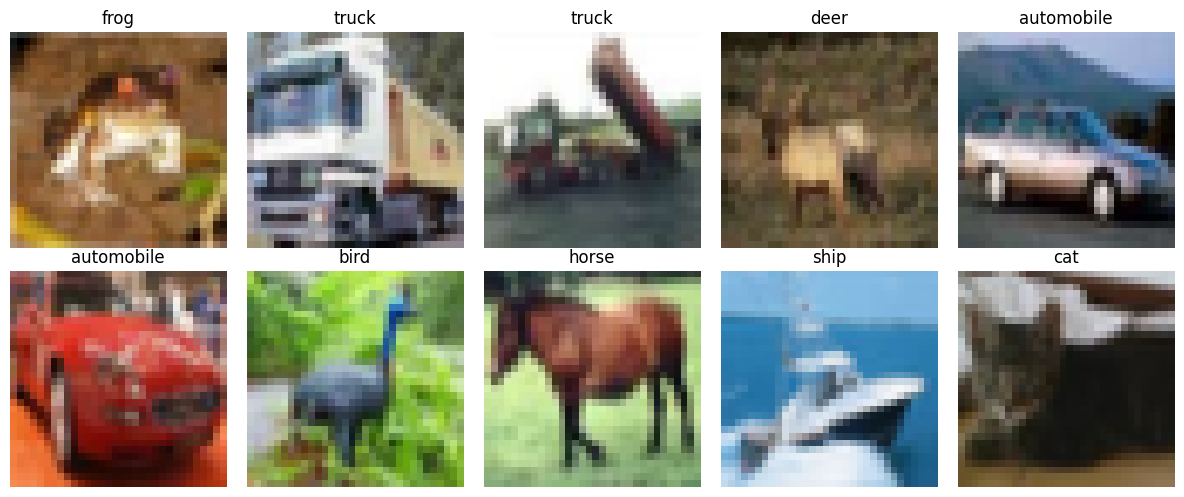

In [12]:
import matplotlib.pyplot as plt

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[int(y_train[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

Build the CNN model

In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense
)

model_cnn = Sequential([
    tf.keras.Input(shape=(32, 32, 3)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

Train the CNN

In [14]:
history_cnn = model_cnn.fit(
    X_train,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 38s 98ms/step - accuracy: 0.3669 - loss: 1.7471 - val_accuracy: 0.4585 - val_loss: 1.5356
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 34s 74ms/step - accuracy: 0.5006 - loss: 1.4030 - val_accuracy: 0.5240 - val_loss: 1.3378
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 50s 104ms/step - accuracy: 0.5576 - loss: 1.2567 - val_accuracy: 0.5765 - val_loss: 1.2507
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step - accuracy: 0.5956 - loss: 1.1492 - val_accuracy: 0.5765 - val_loss: 1.2252
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - accuracy: 0.6257 - loss: 1.0770 - val_accuracy: 0.5960 - val_loss: 1.1758
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 21s 74ms/step - accuracy: 0.6482 - loss: 1.0111 - val_accuracy: 0.5870 - val_loss: 1.2019
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 22s 77ms/step - accuracy: 0.6722 - loss: 0.9487 - val_accuracy: 0.6200 - val_loss: 1.1019
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 42s 80ms/step - accuracy: 0.6858 - loss: 0.9042 

Normalize images and encode labels

In [15]:
# Normalize pixel values to the range 0–1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Convert labels to one-hot encoding
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Training labels shape:", y_train_cat.shape)
print("Testing labels shape:", y_test_cat.shape)

Training labels shape: (20000, 10)
Testing labels shape: (4000, 10)


In [33]:
# Normalize the original images only once
X_train = X_train_full[:20000].astype("float32") / 255.0
y_train = y_train_full[:20000]

X_test = X_test_full[:4000].astype("float32") / 255.0
y_test = y_test_full[:4000]

print("Training pixel range:", X_train.min(), X_train.max())
print("Testing pixel range:", X_test.min(), X_test.max())

Training pixel range: 0.0 1.0
Testing pixel range: 0.0 1.0


Display 10 sample images

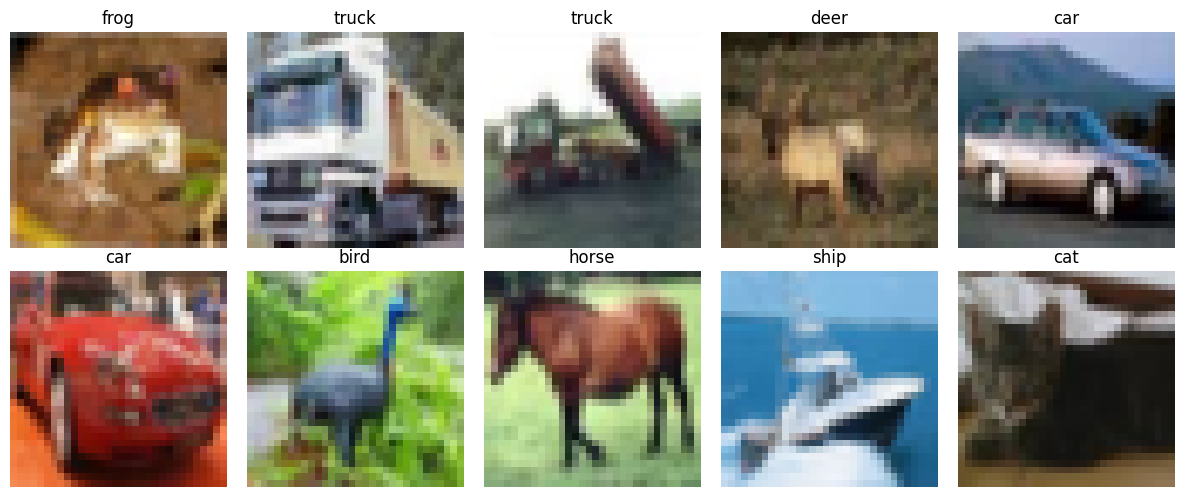

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[int(y_train[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
print(X_train.shape)
print(X_train.min(), X_train.max())
print(y_train[:10])

(20000, 32, 32, 3)
0.0 1.0
[6 9 9 4 1 1 2 7 8 3]


In [37]:
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

Build the CNN model

In [ ]:
model_cnn = Sequential([
    tf.keras.Input(shape=(32, 32, 3)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_cnn.summary()

In [ ]:
import tensorflow as tf

Train the CNN

In [38]:
history_cnn = model_cnn.fit(
    X_train,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 25s 85ms/step - accuracy: 0.7323 - loss: 0.7640 - val_accuracy: 0.6400 - val_loss: 1.0766
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 39s 79ms/step - accuracy: 0.7489 - loss: 0.7206 - val_accuracy: 0.6320 - val_loss: 1.0865
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.7662 - loss: 0.6734 - val_accuracy: 0.6435 - val_loss: 1.0871
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.7778 - loss: 0.6437 - val_accuracy: 0.6530 - val_loss: 1.1084
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.7929 - loss: 0.6020 - val_accuracy: 0.6395 - val_loss: 1.1351
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 44s 83ms/step - accuracy: 0.8119 - loss: 0.5556 - val_accuracy: 0.6430 - val_loss: 1.1469
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.8234 - loss: 0.5197 - val_accuracy: 0.6355 - val_loss: 1.1836
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - accuracy: 0.8374 - loss: 0.4799 - 

Plot accuracy

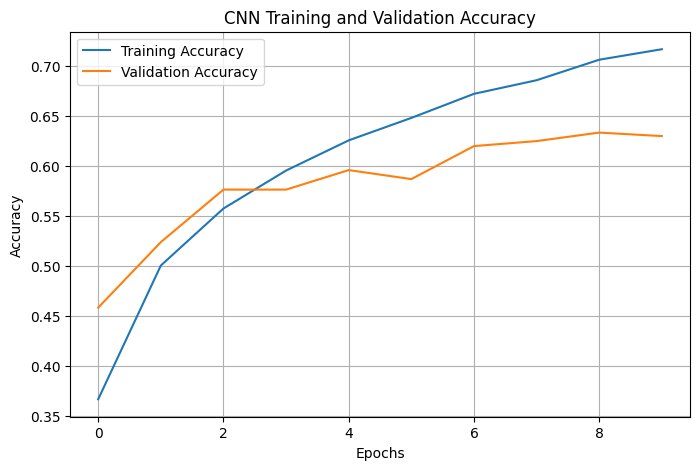

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Plot loss

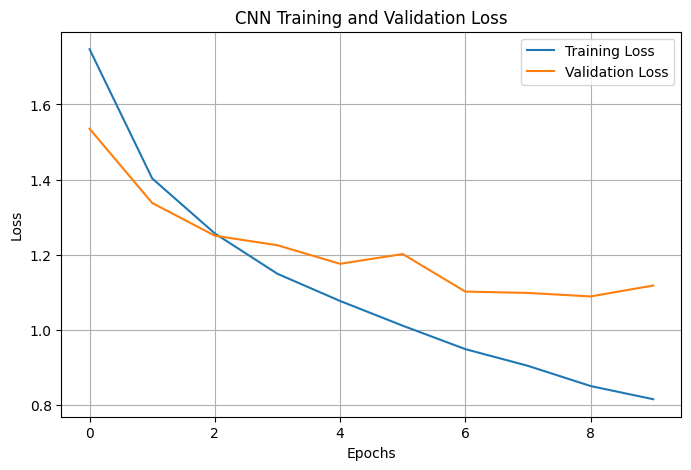

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

Evaluate the CNN

In [41]:
test_loss, test_accuracy = model_cnn.evaluate(
    X_test,
    y_test_cat,
    verbose=0
)

print("CNN Test Accuracy:", round(test_accuracy, 4))
print("CNN Test Accuracy (%):", round(test_accuracy * 100, 2))

CNN Test Accuracy: 0.6325
CNN Test Accuracy (%): 63.25


In [40]:
import numpy as np
from sklearn.metrics import classification_report

y_pred_prob = model_cnn.predict(X_test, verbose=1)
y_pred_cnn = np.argmax(y_pred_prob, axis=1)

print(classification_report(
    y_test,
    y_pred_cnn,
    target_names=class_names,
    zero_division=0
))

125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
              precision    recall  f1-score   support

    airplane       0.67      0.63      0.65       389
         car       0.76      0.80      0.78       392
        bird       0.52      0.52      0.52       426
         cat       0.46      0.47      0.46       389
        deer       0.62      0.45      0.52       400
         dog       0.43      0.63      0.51       388
        frog       0.83      0.65      0.73       396
       horse       0.66      0.73      0.69       397
        ship       0.71      0.81      0.75       408
       truck       0.82      0.64      0.72       415

    accuracy                           0.63      4000
   macro avg       0.65      0.63      0.63      4000
weighted avg       0.65      0.63      0.63      4000



Display 10 test predictions

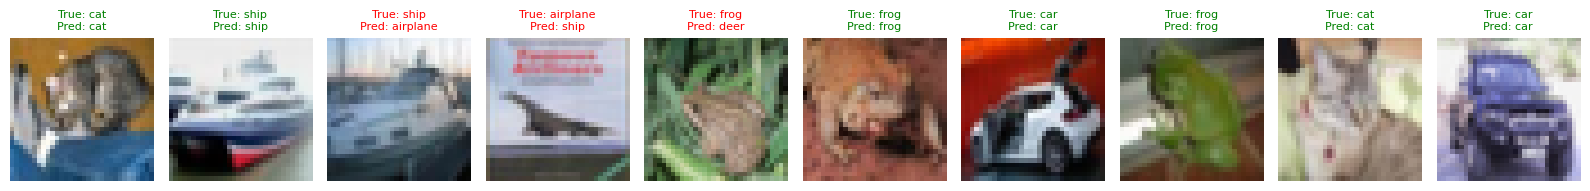

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 5))

for i in range(10):
    true_label = int(y_test[i])
    predicted_label = int(y_pred_cnn[i])

    title_color = "green" if true_label == predicted_label else "red"

    plt.subplot(1, 10, i + 1)
    plt.imshow(X_test[i])
    plt.title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[predicted_label]}",
        color=title_color,
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Save your model

In [43]:
model_cnn.save("cnn_cifar10_model.h5")

print("CNN model saved successfully!")

CNN model saved successfully!


Markdown reflection

### Reflection – CNN on CIFAR-10

In this project, I built a Convolutional Neural Network (CNN) to classify images from the CIFAR-10 dataset into 10 different classes. I used 20,000 training images and 4,000 testing images as required. The images were normalized by dividing pixel values by 255.

The model contains two convolutional layers, two max-pooling layers, a flatten layer, and two dense layers. I used ReLU activation in the hidden layers and softmax in the output layer. The model was compiled with the Adam optimizer and categorical cross-entropy loss.

I trained the model for 10 epochs with a batch size of 64. I evaluated its performance using test accuracy, loss, and a classification report containing precision, recall, and F1-score. I also displayed sample predictions, using green titles for correct predictions and red titles for incorrect predictions.

This project helped me understand how CNNs extract image features and how pooling reduces feature-map dimensions. One limitation is that small, low-resolution images can be difficult to classify, and the model may confuse visually similar classes. More training data, data augmentation, and regularization could potentially improve performance.

## Step 4- RNN

In [44]:
import pandas as pd

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df_airline = pd.read_csv(url)

print(df_airline.head())
print("Dataset shape:", df_airline.shape)

     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121
Dataset shape: (144, 2)


RNN Airline Passenger Prediction

Prepare the data

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Select passenger numbers
passengers = df_airline["Passengers"].values.reshape(-1, 1)

# Scale values between 0 and 1
scaler_rnn = MinMaxScaler(feature_range=(0, 1))
passengers_scaled = scaler_rnn.fit_transform(passengers)

print("Original data shape:", passengers.shape)
print("Scaled data shape:", passengers_scaled.shape)
print("First 5 scaled values:\n", passengers_scaled[:5])

Original data shape: (144, 1)
Scaled data shape: (144, 1)
First 5 scaled values:
 [[0.01544402]
 [0.02702703]
 [0.05405405]
 [0.04826255]
 [0.03281853]]


Create sequences using 12 months

In [46]:
look_back = 12

def create_sequences(data, look_back):
    X, y = [], []

    for i in range(len(data) - look_back):
        X.append(data[i:i + look_back, 0])
        y.append(data[i + look_back, 0])

    return np.array(X), np.array(y)

X_rnn, y_rnn = create_sequences(passengers_scaled, look_back)

print("X shape:", X_rnn.shape)
print("y shape:", y_rnn.shape)

X shape: (132, 12)
y shape: (132,)


Split into training and testing data

In [47]:
split_index = int(len(X_rnn) * 0.8)

X_train_rnn = X_rnn[:split_index]
X_test_rnn = X_rnn[split_index:]

y_train_rnn = y_rnn[:split_index]
y_test_rnn = y_rnn[split_index:]

# RNN expects input shape: (samples, time steps, features)
X_train_rnn = X_train_rnn.reshape(-1, look_back, 1)
X_test_rnn = X_test_rnn.reshape(-1, look_back, 1)

print("Training input:", X_train_rnn.shape)
print("Testing input:", X_test_rnn.shape)

Training input: (105, 12, 1)
Testing input: (27, 12, 1)


Build the SimpleRNN model

In [48]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

model_rnn = Sequential([
    tf.keras.Input(shape=(12, 1)),
    SimpleRNN(50, activation="tanh"),
    Dense(1)
])

model_rnn.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model_rnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

Train the model

In [49]:
history_rnn = model_rnn.fit(
    X_train_rnn,
    y_train_rnn,
    epochs=50,
    batch_size=16,
    shuffle=False,
    verbose=1
)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - loss: 0.0048
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0029   
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0051
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0062
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0074
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0057    
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0015
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0018    
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - loss: 0.0016  
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - loss: 9.7159e-04
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0010  
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 9.7657e-04
Epoch 13/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 8.5872e-04 
Epoch 14/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 8.3734e-04
Epoch 15/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 8.1942e-0

Plot the training loss

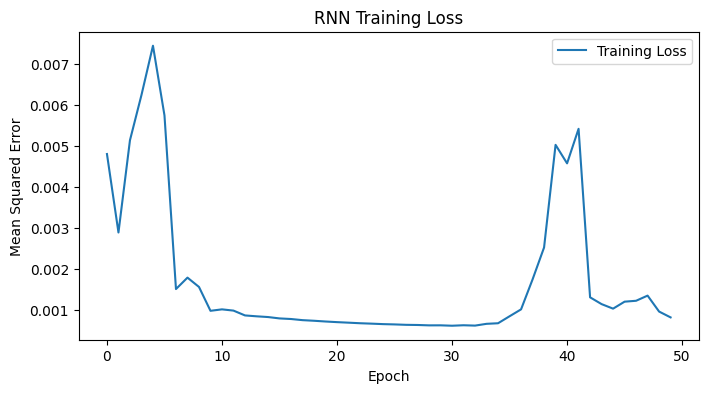

In [50]:
plt.figure(figsize=(8, 4))

plt.plot(history_rnn.history["loss"], label="Training Loss")
plt.title("RNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.show()

Make predictions and calculate RMSE

In [51]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Predict on training and testing data
train_predictions = model_rnn.predict(X_train_rnn, verbose=0)
test_predictions = model_rnn.predict(X_test_rnn, verbose=0)

# Convert predictions back to actual passenger counts
train_predictions_actual = scaler_rnn.inverse_transform(train_predictions)
test_predictions_actual = scaler_rnn.inverse_transform(test_predictions)

y_train_actual = scaler_rnn.inverse_transform(
    y_train_rnn.reshape(-1, 1)
)
y_test_actual = scaler_rnn.inverse_transform(
    y_test_rnn.reshape(-1, 1)
)

# Calculate test RMSE
rmse = np.sqrt(
    mean_squared_error(y_test_actual, test_predictions_actual)
)

print(f"Test RMSE: {rmse:.2f} passengers")

Test RMSE: 42.54 passengers


Plot actual vs predicted passengers

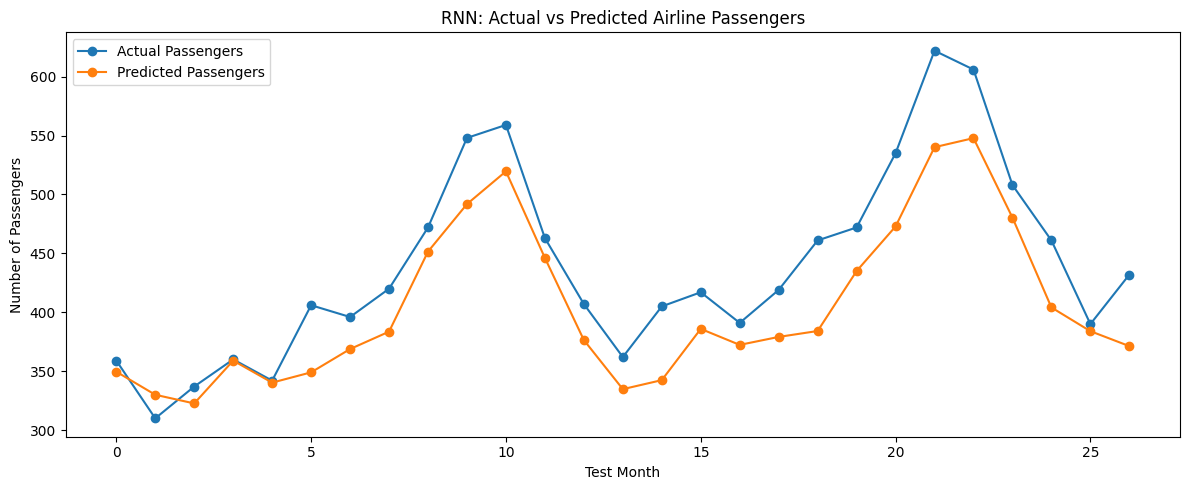

In [52]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test_actual,
    label="Actual Passengers",
    marker="o"
)
plt.plot(
    test_predictions_actual,
    label="Predicted Passengers",
    marker="o"
)

plt.title("RNN: Actual vs Predicted Airline Passengers")
plt.xlabel("Test Month")
plt.ylabel("Number of Passengers")
plt.legend()
plt.tight_layout()
plt.show()

Save the RNN model

In [53]:
model_rnn.save("rnn_airline_model.h5")
print("RNN model saved successfully!")

RNN model saved successfully!


Add your reflection

### Reflection – RNN Airline Passenger Prediction

In this project, I built a Simple Recurrent Neural Network (RNN) to predict monthly airline passenger numbers using historical data from 1949 to 1960. The dataset contained 144 monthly records.

I scaled the passenger counts between 0 and 1 using MinMaxScaler. I then created sequences using the previous 12 months to predict the next month's passenger count. I split the sequences chronologically, using 80% for training and 20% for testing, without shuffling the data.

The model used a SimpleRNN layer with 50 units and tanh activation, followed by a Dense output layer. I trained it for 50 epochs with a batch size of 16 using the Adam optimizer and mean squared error loss.

I evaluated the predictions using RMSE after converting the scaled values back into passenger counts. I also plotted actual versus predicted passenger numbers to compare the model's performance.

This project helped me understand how RNNs use sequential information to make predictions. A limitation is that the dataset is small and passenger numbers have seasonal patterns and a long-term upward trend. A more advanced model or additional training data might improve forecasting accuracy.

## Step 5- Transformer sentiment analysis

Install the required library

In [55]:
%pip install transformers

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.0 MB ? eta -:--:--
   ---------


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Load the pretrained sentiment pipeline

In [56]:
from transformers import pipeline

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

print("Sentiment model loaded successfully!")

C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Admin\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an

Sentiment model loaded successfully!


Create 25 reviews

In [57]:
reviews = [
    # 10 Positive reviews
    ("The food was amazing and the staff were very friendly.", "POS"),
    ("I absolutely loved this movie.", "POS"),
    ("The product quality is excellent.", "POS"),
    ("This is the best experience I have ever had.", "POS"),
    ("The delivery was fast and the packaging was perfect.", "POS"),
    ("I am very happy with my purchase.", "POS"),
    ("The service was wonderful and professional.", "POS"),
    ("This phone works perfectly and has a great camera.", "POS"),
    ("The trip was beautiful and unforgettable.", "POS"),
    ("I highly recommend this place to everyone.", "POS"),

    # 10 Negative reviews
    ("The food was cold and tasted terrible.", "NEG"),
    ("I hated this movie; it was boring.", "NEG"),
    ("The product broke after one day.", "NEG"),
    ("This was the worst experience ever.", "NEG"),
    ("My delivery was late and the package was damaged.", "NEG"),
    ("I am very disappointed with this purchase.", "NEG"),
    ("The staff were rude and unhelpful.", "NEG"),
    ("The phone battery is terrible and drains quickly.", "NEG"),
    ("The room was dirty and uncomfortable.", "NEG"),
    ("I would not recommend this product.", "NEG"),

    # 5 Ambiguous / Neutral reviews
    ("The food was okay, nothing special.", "NEU"),
    ("The movie was long but had some good scenes.", "NEU"),
    ("The product arrived yesterday.", "NEU"),
    ("The service was average.", "NEU"),
    ("The phone is expensive but has many features.", "NEU"),
]

print("Total reviews:", len(reviews))

Total reviews: 25


Run sentiment analysis

In [58]:
import pandas as pd

sentences = [review[0] for review in reviews]
true_sentiments = [review[1] for review in reviews]

predictions = sentiment_pipeline(
    sentences,
    batch_size=8,
    truncation=True
)

results_df = pd.DataFrame({
    "Sentence": sentences,
    "True_Sentiment": true_sentiments,
    "Predicted_Label": [
        prediction["label"] for prediction in predictions
    ],
    "Confidence_Score": [
        round(prediction["score"], 4) for prediction in predictions
    ]
})

results_df.head(10)

,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
0,The food was amazing and the staff were very f...,POS,POSITIVE,0.9999
1,I absolutely loved this movie.,POS,POSITIVE,0.9999
2,The product quality is excellent.,POS,POSITIVE,0.9999
3,This is the best experience I have ever had.,POS,POSITIVE,0.9998
4,The delivery was fast and the packaging was pe...,POS,POSITIVE,0.9999
5,I am very happy with my purchase.,POS,POSITIVE,0.9999
6,The service was wonderful and professional.,POS,POSITIVE,0.9999
7,This phone works perfectly and has a great cam...,POS,POSITIVE,0.9999
8,The trip was beautiful and unforgettable.,POS,POSITIVE,0.9999
9,I highly recommend this place to everyone.,POS,POSITIVE,0.9999


Count correct predictions for the 20 clear reviews

In [59]:
clear_reviews = results_df[
    results_df["True_Sentiment"].isin(["POS", "NEG"])
].copy()

clear_reviews["Correct"] = (
    clear_reviews["True_Sentiment"]
    == clear_reviews["Predicted_Label"].map({
        "POSITIVE": "POS",
        "NEGATIVE": "NEG"
    })
)

correct_count = int(clear_reviews["Correct"].sum())

print("Clear reviews:", len(clear_reviews))
print("Correct predictions:", correct_count, "out of 20")
print(f"Accuracy: {correct_count / 20 * 100:.2f}%")

Clear reviews: 20
Correct predictions: 20 out of 20
Accuracy: 100.00%


Plot the sentiment results

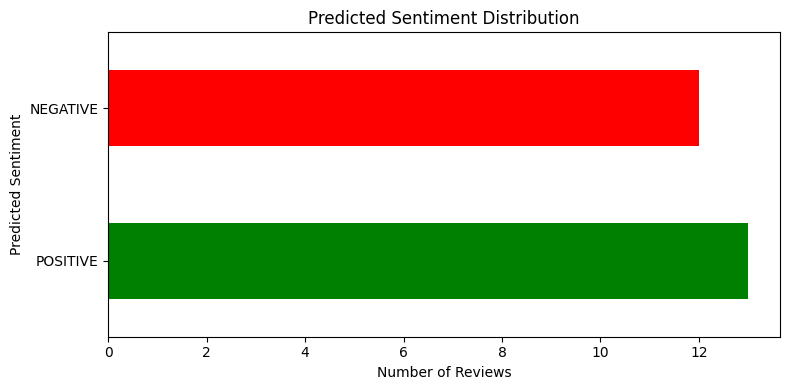

In [60]:
import matplotlib.pyplot as plt

sentiment_counts = results_df["Predicted_Label"].value_counts()

colors = [
    "green" if label == "POSITIVE" else "red"
    for label in sentiment_counts.index
]

plt.figure(figsize=(8, 4))
sentiment_counts.plot(kind="barh", color=colors)
plt.title("Predicted Sentiment Distribution")
plt.xlabel("Number of Reviews")
plt.ylabel("Predicted Sentiment")
plt.tight_layout()
plt.show()

Examine the 5 ambiguous reviews

In [61]:
results_df[results_df["True_Sentiment"] == "NEU"]

,Sentence,True_Sentiment,Predicted_Label,Confidence_Score
20,"The food was okay, nothing special.",NEU,NEGATIVE,0.9834
21,The movie was long but had some good scenes.,NEU,POSITIVE,0.9988
22,The product arrived yesterday.,NEU,POSITIVE,0.9814
23,The service was average.,NEU,NEGATIVE,0.9087
24,The phone is expensive but has many features.,NEU,POSITIVE,0.9931


Save the results

In [62]:
results_df.to_csv("transformer_sentiment_results.csv", index=False)
print("Sentiment results saved successfully!")

Sentiment results saved successfully!


Add your reflection

### Reflection – Transformer-Based Sentiment Analysis

In this project, I used a pretrained DistilBERT model to perform sentiment analysis on 25 self-written reviews. The reviews included 10 positive, 10 negative, and 5 ambiguous or neutral examples.

I used the Hugging Face sentiment-analysis pipeline with the pretrained `distilbert-base-uncased-finetuned-sst-2-english` model. I did not fine-tune the model. The pipeline returned a predicted sentiment label and a confidence score for each review.

The model correctly classified all 20 clear positive and negative reviews, achieving 100% accuracy on this small, manually created set. I also created a DataFrame containing each sentence, its true sentiment, the predicted label, and the confidence score. A horizontal bar chart displayed the distribution of predicted sentiments.

One limitation is that this model supports only positive and negative labels, so it cannot directly classify neutral sentiment. Its performance on a small set of self-written reviews does not guarantee similar accuracy on real-world data. It may also struggle with sarcasm, context, Indian English expressions, and mixed opinions. Testing on a larger and more diverse dataset would provide a more reliable evaluation.

Save the model information

In [64]:
print("Transformer model:", "distilbert-base-uncased-finetuned-sst-2-english")
print("Fine-tuning performed: No")
print("Clear review accuracy:", f"{correct_count / 20 * 100:.2f}%")

Transformer model: distilbert-base-uncased-finetuned-sst-2-english
Fine-tuning performed: No
Clear review accuracy: 100.00%


Final results summary

Project	Model / Method	Final result
1. Diabetes prediction	ANN	Test accuracy: 74.03%; F1-score: 0.6226
2. Image processing	OpenCV	5 images processed; 5×5 output grid created
3. CIFAR-10 classification	CNN	10 epochs; record your final corrected test accuracy
4. Airline passenger prediction	SimpleRNN	Test RMSE: 42.54 passengers
5. Sentiment analysis	DistilBERT	20/20 clear reviews correct; 100% on this small test set